In [454]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

k = 3

df = pd.read_csv("Instagram visits clustering.csv")
df = df.drop(columns=['User ID'])
df.describe()

,Instagram visit score,Spending_rank(0 to 100)
count,2600.000000,2600.000000
mean,63.323462,42.848408
std,26.579760,28.758349
min,5.000000,0.940709
25%,38.000000,19.452098
50%,72.000000,28.013082
75%,86.000000,72.116945
max,118.000000,107.349821


In [455]:
centroids = df.sample(n=k).values
points = df.values

In [456]:
points.shape

(2600, 2)

In [457]:
centroids.shape

(3, 2)

In [458]:
diff = points[:, None, :] - centroids[None, :, :]   # (2600, 3, 2)
squared = diff ** 2                                  # (2600, 3, 2)
distances = squared.sum(axis=2)                      # (2600, 3)
labels = distances.argmin(axis=1)                    # (2600,)

In [459]:
old_centroids = centroids.copy()
old_centroids

array([[32.        , 41.00401185],
       [59.        , 63.66034551],
       [79.        , 83.88192128]])

In [460]:
centroids = np.zeros((k, points.shape[1]))
for j in range(k):
    mask = (labels == j)
    punti_del_cluster_j = points[mask]
    centroids[j] = np.mean(punti_del_cluster_j, axis=0)

In [461]:
max_iter = 20
k  = 3
tol = 0.0001
centroids = df.sample(n=k, random_state=42).values
points = df.values

for i in range(max_iter):
    diff = points[:, None, :] - centroids[None, :, :]
    squared = diff ** 2     
    distances = squared.sum(axis=2)  
    labels = distances.argmin(axis=1)    
    old_centroids = centroids.copy()
    centroids = np.zeros((k, points.shape[1]))
    for j in range(k):
        mask = (labels == j)
        punti_del_cluster_j = points[mask]
        centroids[j] = np.mean(punti_del_cluster_j, axis=0)
    
    shift = np.sqrt(((centroids - old_centroids) ** 2).sum(axis=1))  # distanza per ogni centroide, shape (k,)
    total_shift = shift.sum()  # un solo numero
    if total_shift < tol:
        break

In [462]:
%matplotlib inline

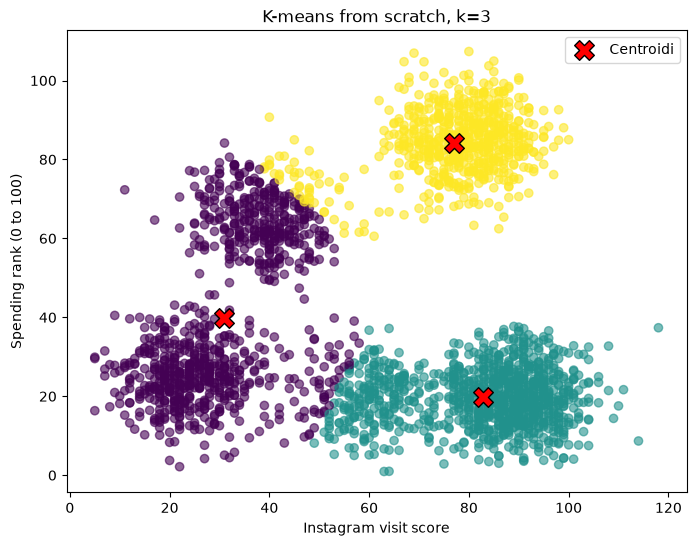

In [463]:
plt.figure(figsize=(8, 6))
plt.scatter(points[:, 0], points[:, 1], c=labels, cmap='viridis', alpha=0.6)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, edgecolor='black', label='Centroidi')
plt.xlabel('Instagram visit score')
plt.ylabel('Spending rank (0 to 100)')
plt.title(f'K-means from scratch, k={k}')
plt.legend()
plt.show()

In [ ]:
def kmeans_from_scratch(k):
    max_iter = 20
    tol = 0.0001
    centroids = df.sample(n=k).values
    points = df.values

    for i in range(max_iter):
        diff = points[:, None, :] - centroids[None, :, :]
        squared = diff ** 2
        distances = squared.sum(axis=2)
        labels = distances.argmin(axis=1)

        old_centroids = centroids.copy()
        centroids = np.zeros((k, points.shape[1]))
        for j in range(k):
            mask = (labels == j)
            punti_del_cluster_j = points[mask]
            centroids[j] = np.mean(punti_del_cluster_j, axis=0)

        shift = np.sqrt(((centroids - old_centroids) ** 2).sum(axis=1))
        total_shift = shift.sum()
        if total_shift < tol:
            break

    # ricalcolo finale con i centroidi aggiornati, per allineare labels e J ai centroidi definitivi
    diff = points[:, None, :] - centroids[None, :, :]
    distances = (diff ** 2).sum(axis=2)
    labels = distances.argmin(axis=1)
    J = distances.min(axis=1).sum()

    return labels, centroids, J

In [465]:
J_values = []

for k in range(1, 11):
    labels, centroids, J = kmeans_from_scratch(k)
    J_values.append(J)

In [466]:
J_values

[np.float64(3985634.77967174),
 np.float64(2079619.3276164345),
 np.float64(847038.4246349013),
 np.float64(440248.7915180186),
 np.float64(278407.5245719684),
 np.float64(251733.57496504093),
 np.float64(231465.99004380457),
 np.float64(213293.61933085817),
 np.float64(191830.04031837767),
 np.float64(177962.88803933156)]

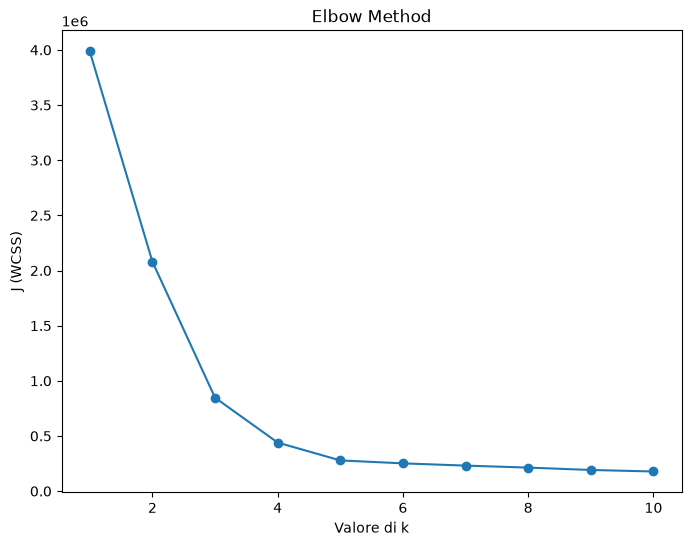

In [467]:
plt.figure(figsize=(8, 6))
plt.plot(range(1, 11), J_values, marker='o')
plt.xlabel('Valore di k')
plt.ylabel('J (WCSS)')
plt.title('Elbow Method')
plt.show()

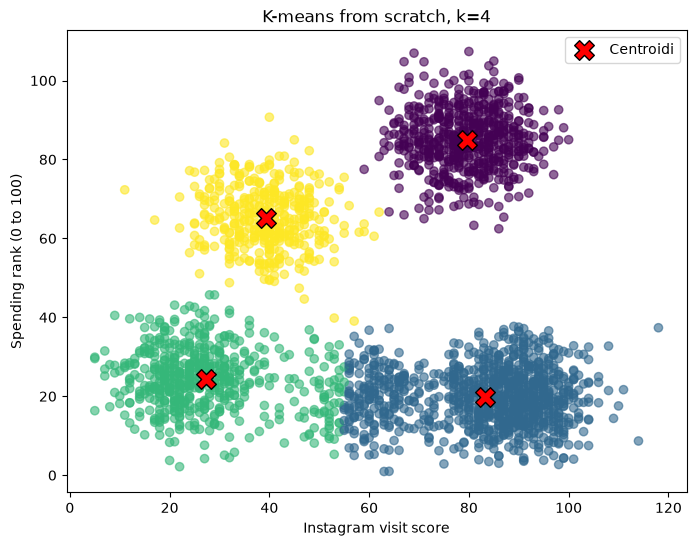

In [468]:
labels_new, centroids_new, j_new = kmeans_from_scratch(k=4)
points_new = df.values

plt.figure(figsize=(8, 6))
plt.scatter(points_new[:, 0], points_new[:, 1], c=labels_new, cmap='viridis', alpha=0.6)
plt.scatter(centroids_new[:, 0], centroids_new[:, 1], c='red', marker='X', s=200, edgecolor='black', label='Centroidi')
plt.xlabel('Instagram visit score')
plt.ylabel('Spending rank (0 to 100)')
plt.title(f'K-means from scratch, k=4')
plt.legend()
plt.show()